In [1]:
import os
import sys
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

import scipy as sp
import numpy as np
import pandas as pd
import colorcet as cc
import warnings
import natsort as ns

from matplotlib import font_manager as fm
from matplotlib import rcParams
font_dir = os.path.abspath('/home/leethargic/resource/Arial')
for font_file in fm.findSystemFonts(fontpaths=[font_dir]):
    fm.fontManager.addfont(font_file)
    
print(mpl.font_manager.findfont('Arial', rebuild_if_missing=True))
plt.rcParams['font.family'] = 'Arial'
print(mpl.rcParams['font.family'])

mpl.rcParams["grid.linewidth"] = 0.5
mpl.rcParams["lines.linewidth"] = 1.0
plt.rcParams["axes.axisbelow"] = True
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

/usr/share/fonts/truetype/msttcorefonts/Arial.ttf
['Arial']


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

AnnData object with n_obs × n_vars = 515250 × 22990
    obs: 'sample_num', 'sample', 'patient_id', 'sample_IOT_DAAN', 'disease', 'gender', 'age', 'batch', 'biopsy_site', 'tissue', 'histology', 'driver_oncogene', 'tumor_pdl1_expression', 'io_preorpost', 'pd_drug', 'stage_initial', 'stage', 'chemo_date', 'biopsy_date', 'ctb_days', 'pfs_days', 'group1', 'group2', 'group3', 'Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'S_score', 'G2M_score', 'phase', 'louvain_res1', 'louvain_res2', 'scVI_pred', 'coarse_ann', 'coarse_ann_num', 'louvain_res3', 'annotation', 'umap_density_Group1', 'umap_density_Group2', 'umap_density_Group3', 'umap_density_Group4', 'umap_density_Group5', 'Naiveness_score', 'Residency_score', 'Exhaustion_score', 'Cytotoxicity_score', 'annotation2', 'type', 'file', 'time', 'pa

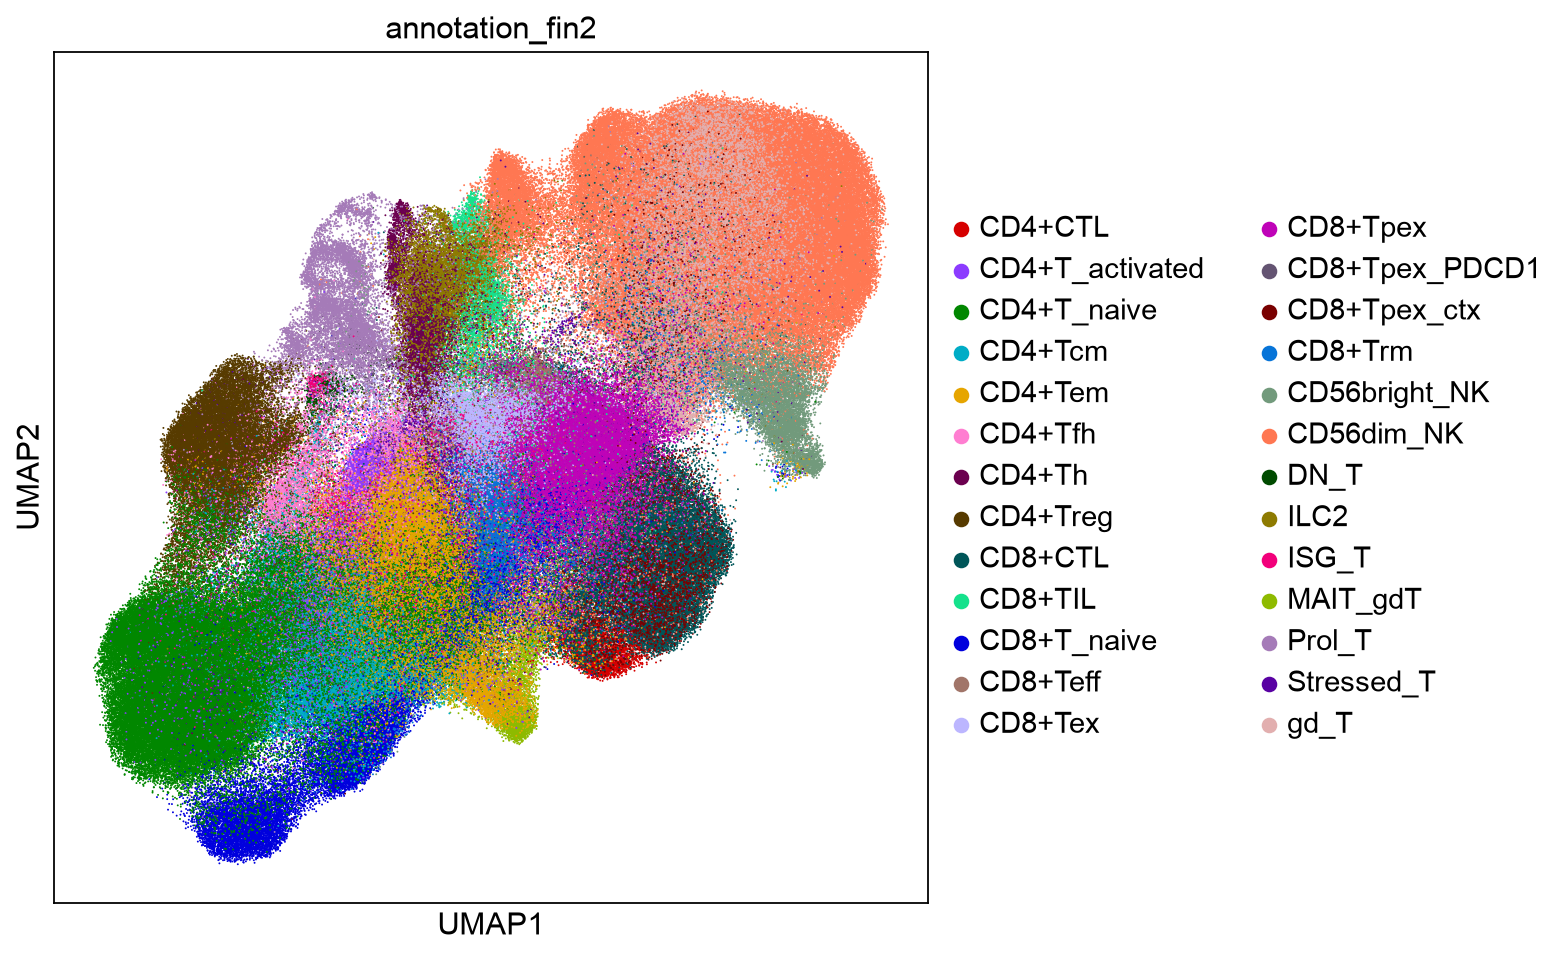

In [3]:
adata = sc.read('/data/projects/Lung_Cancer_IOT/Lung_Cancer_PBMC/0_.final_fig/lc_total_fin_ctx2.h5ad')
print(adata)
sc.set_figure_params(figsize=(7,7))
sc.pl.umap(adata, color=['annotation_fin2'], s=3)

In [4]:
df = pd.read_excel('/home/leethargic/CHJ_OLINK/LC_PBMC_pt_info_HSim_CanComm_updated.xlsx')
df

,sample_id,age,sex,Binarized response,RECIST response,response,PFS_censor,PFS,OS_censor,OS,...,histology,PDL1_res,smoking_category,smoking_amount,regimen,Line number,ECOG performance status,Molecular features,Treatment period (in weeks),new_id
0,IO_SC_001,79.1,M,DCB,SD,SD,1,489,1,489,...,LUSC,40.0,2,25.0,Pembrolizumab,1,1,NaN,1,ID001
1,IO_SC_002,48.7,M,NCB,SD,SD(MI),1,113,1,445,...,LUAD,90.0,1,20.0,Pembrolizumab,1,1,RET Fusion,1,ID002
2,IO_SC_004,82.6,M,DCB,PR,PR,1,478,1,478,...,LUAD,0.0,1,40.0,Atezolizumab,2,2,NaN,3,ID003
3,IO_SC_006,69.3,M,NCB,PD,PD,1,68,1,467,...,LUSC,0.0,1,20.0,Atezolizumab,1,1,NaN,1,ID004
4,IO_SC_007,81.5,M,DCB,PR,PR,0,760,1,1089,...,LUAD,90.0,1,50.0,Atezollizumab,1,1,NaN,4,ID005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,IO_SC_114,72.6,M,DCB,PR,PR,1,684,1,684,...,LUSC,60.0,1,40.0,Pembrolizumab,0,1,NaN,2,ID069
69,IO_SC_116,67.4,M,NCB,PD,PD,1,21,1,73,...,LUAD,20.0,1,45.0,Pembrolizumab,1,1,NaN,3,ID070
70,IO_SC_118,64.4,M,NCB,PD,PD,1,39,1,126,...,LUAD,0.0,1,30.0,Atezolizumab,1,1,KRAS(G12D),3,ID071
71,IO_SC_126,59.6,M,NCB,PD,PD,1,51,1,198,...,LUAD,0.0,1,20.0,Nivolumab,3,1,EGFR(L858R),2,ID072


In [5]:
pfs_mapper = dict(zip(df['sample_id'],df['PFS']))
adata.obs['PFS'] = adata.obs['patient'].map(pfs_mapper).astype('float')
adata.obs['PFS']

pfs_censor = dict(zip(df['sample_id'],df['PFS_censor']))
adata.obs['PFS_censor'] = adata.obs['patient'].map(pfs_censor).astype('float')
adata.obs['PFS_censor']

bin_mapper = dict(zip(df['sample_id'],df['Binarized response']))
adata.obs['response2'] = adata.obs['patient'].map(bin_mapper)
adata.obs['response2']

pd_mapper = dict(zip(df['sample_id'],df['PDL1_res']))
adata.obs['PDL1'] = adata.obs['patient'].map(pd_mapper)
adata.obs['PDL1']

os_mapper = dict(zip(df['sample_id'],df['OS']))
adata.obs['OS'] = adata.obs['patient'].map(os_mapper)
adata.obs['OS']

os_mapper2 = dict(zip(df['sample_id'],df['OS_censor']))
adata.obs['OS_censor'] = adata.obs['patient'].map(os_mapper2)
adata.obs['OS_censor']

GGCCGATAGTTAACGA-1_M7_1st       0.0
ACTGAACAGGCTAGCA-1_M6_1st       1.0
CGATTGAAGATGTGGC-1_M8_1st       0.0
CGAGAAGTCTTCGGTC-1_2-IO_1st     1.0
CTAAGACCACATGGGA-1_7-IO_base    1.0
                               ... 
TTTGTCAAGTCCGTAT-100            NaN
TTTGTCACACATCCGG-100            NaN
TTTGTCACAGACAGGT-100            NaN
TTTGTCAGTGTGACCC-100            NaN
TTTGTCAGTTCCACGG-100            NaN
Name: OS_censor, Length: 515250, dtype: float64

In [6]:
# remove samples with missing PFS, removing the tissue samples
adata=adata[~adata.obs['PFS'].isna()]
adata

View of AnnData object with n_obs × n_vars = 259492 × 22990
    obs: 'sample_num', 'sample', 'patient_id', 'sample_IOT_DAAN', 'disease', 'gender', 'age', 'batch', 'biopsy_site', 'tissue', 'histology', 'driver_oncogene', 'tumor_pdl1_expression', 'io_preorpost', 'pd_drug', 'stage_initial', 'stage', 'chemo_date', 'biopsy_date', 'ctb_days', 'pfs_days', 'group1', 'group2', 'group3', 'Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'S_score', 'G2M_score', 'phase', 'louvain_res1', 'louvain_res2', 'scVI_pred', 'coarse_ann', 'coarse_ann_num', 'louvain_res3', 'annotation', 'umap_density_Group1', 'umap_density_Group2', 'umap_density_Group3', 'umap_density_Group4', 'umap_density_Group5', 'Naiveness_score', 'Residency_score', 'Exhaustion_score', 'Cytotoxicity_score', 'annotation2', 'type', 'file', 'ti

In [7]:
from lifelines.statistics import logrank_test
from collections import Counter
import random
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
all_candidate_genes = [
    "NKG7", "GZMH", "CCL5", "CST7", "FGFBP2", "GZMA", "GZMB", "PRF1", "CTSW", "KLRD1", "S100A4", "SRGN", "CD8A",
    "GNLY", "PLEK", "FCRL6", "GZMM", "CCL4", "ZEB2", "KLF6", "C12orf75", "LGALS1", "BHLHE40", "ADGRG1", "CTSC",
    "APOBEC3G", "EFHD2", "ZFP36", "SERTAD1", "GNG2", "SPON2", "PRSS23", "HLA-DRB1", "TSC22D3", "ID2", "S1PR5",
    "C1orf21", "HOPX", "MYADM", "NR4A2", "APMAP", "TGFB1", "IFNG", "TUBB4B", "RHOC", "LAIR2", "PPP1R15A", "SERTAD3",
    "KLRG1", "TUBA4A", "TNFAIP3", "CX3CR1", "FCGR3A", "FGR", "CLIC3", "TTC38", "FOS", "TENT5C", "ADRB2", "CMC1",
    "JMJD6", "CCL4L2", "ZNF683", "MAP3K8", "MIDN", "AGPAT4", "OASL", "DDIT3", "FOSL2", "PTMS", "LILRB1", "PTGDR",
    "ITGAM", "TRGV8", "XCL2", "KLRB1", "ADGRG5", "CD160", "ATF3", "TRGV5", "KLRF1", "NR4A3", "XCL1", "PDGFD", 
    "KIF19", "GALNT3", "GPR141", "EPHX4", "DUSP5", "ENPP5", "TRBV24-1", "TRBV16"
]

candidate_genes = sorted(list(set(all_candidate_genes)))
target_celltypes = ['CD8+Tpex_ctx']

temp = adata[adata.obs['annotation_fin2'].isin(target_celltypes)].copy()
sc.pp.filter_genes(temp, min_cells=1)
sc.pp.filter_genes(temp, min_counts=5)

valid_candidates = sorted([g for g in candidate_genes if g in temp.var_names])
sc.settings.verbosity = 0
sc.settings.seed = 42

def get_survival_score(gene_list):
    if not gene_list:
        return -999.0
    
    sorted_gene_list = sorted(list(gene_list))
    sc.tl.score_genes(
        temp,
        gene_list=sorted_gene_list,
        score_name='temp_score',
        use_raw=False,
        random_state=42, 
        ctrl_size=len(sorted_gene_list)
    )
    
    patient_df = temp.obs.groupby('patient').agg(
        mean_score=('temp_score', 'mean'),
        PFS=('PFS', 'first'),
        PFS_censor=('PFS_censor', 'first')
    ).reset_index()
    
    patient_df = patient_df.dropna(subset=['PFS', 'PFS_censor', 'mean_score'])
    num_patients = len(patient_df)
    num_events = (patient_df['PFS_censor'] == 1).sum()
    if num_patients < 5 or num_events < 2:
        return -999.0
        
    median_score = patient_df['mean_score'].median()
    if patient_df['mean_score'].min() == patient_df['mean_score'].max():
        return -999.0

    group_high = patient_df[patient_df['mean_score'] >= median_score]
    group_low = patient_df[patient_df['mean_score'] < median_score]
    
    if len(group_high) == 0 or len(group_low) == 0:
        return -999.0
        
    try:
        results = logrank_test(
            group_high['PFS'], group_low['PFS'],
            event_observed_A=group_high['PFS_censor'],
            event_observed_B=group_low['PFS_censor']
        )
        p_val = results.p_value
        if pd.isna(p_val) or p_val == 0:
            return -999.0
        return -np.log10(p_val)
    except Exception:
        return -999.0

def run_simulated_annealing(run_seed):
    local_random = random.Random(run_seed)
    np.random.seed(run_seed)

    k_init = max(1, len(valid_candidates) // 5)
    current_included = set(local_random.sample(valid_candidates, k=k_init))
    
    current_score = get_survival_score(current_included)
    best_included = set(current_included)
    best_score = current_score

    temp_degree = 1.0
    cooling_rate = 0.95
    iterations_per_temp = 10
    min_temp = 0.01

    while temp_degree > min_temp:
        for _ in range(iterations_per_temp):
            toggle_gene = local_random.choice(valid_candidates)
            next_included = set(current_included)

            if toggle_gene in next_included:
                if len(next_included) > 1:
                    next_included.remove(toggle_gene)
            else:
                next_included.add(toggle_gene)

            next_score = get_survival_score(next_included)
            score_diff = next_score - current_score

            if score_diff > 0 or np.exp(score_diff / temp_degree) > local_random.random():
                current_included = next_included
                current_score = next_score

                if current_score > best_score:
                    best_score = current_score
                    best_included = set(next_included)

        temp_degree *= cooling_rate

    return sorted(list(best_included)), best_score

N_RUNS = 20         
CONSENSUS_THRESHOLD = 0.50
gene_selection_counts = Counter()
run_scores = []

for run_idx in range(N_RUNS):
    seed = 42 + run_idx
    best_genes, best_score = run_simulated_annealing(run_seed=seed)
    
    gene_selection_counts.update(best_genes)
    run_scores.append(best_score)
    
    print(f"Run {run_idx + 1:02d}/{N_RUNS} (Seed {seed}) | Best Score (-log10 p): {best_score:.4f} | Genes Count: {len(best_genes)}")

min_appearances = int(N_RUNS * CONSENSUS_THRESHOLD)
consensus_gene_list = sorted([
    gene for gene, count in gene_selection_counts.items() 
    if count >= min_appearances
])

consensus_score = get_survival_score(consensus_gene_list)

print('\n' + '=' * 60)
print('=== Consensus Optimal Survival Gene Set ===')
print('=' * 60)
print(f'Total Runs Conducted: {N_RUNS}')
print(f'Inclusion Cutoff: Present in >= {min_appearances} runs ({CONSENSUS_THRESHOLD*100:.0f}%)')
print(f'Consensus Set Size: {len(consensus_gene_list)} genes')
print(f'Consensus Set Score (-log10 p): {consensus_score:.4f}')
if consensus_score > -999:
    print(f'Consensus p-value: {10**(-consensus_score):.4e}')
print(f'Final Gene List: {consensus_gene_list}')
print("\nGene Inclusion Frequencies across runs:")

for gene, count in sorted(gene_selection_counts.items(), key=lambda x: x[1], reverse=True):
    status = "[SELECTED]" if count >= min_appearances else "          "
    print(f"{status} {gene:<12}: {count}/{N_RUNS} runs ({count/N_RUNS*100:.1f}%)")

Run 01/20 (Seed 42) | Best Score (-log10 p): 3.1009 | Genes Count: 49
Run 02/20 (Seed 43) | Best Score (-log10 p): 2.5274 | Genes Count: 51
Run 03/20 (Seed 44) | Best Score (-log10 p): 2.7910 | Genes Count: 52
Run 04/20 (Seed 45) | Best Score (-log10 p): 3.6786 | Genes Count: 37
Run 05/20 (Seed 46) | Best Score (-log10 p): 3.2336 | Genes Count: 38
Run 06/20 (Seed 47) | Best Score (-log10 p): 3.6482 | Genes Count: 47
Run 07/20 (Seed 48) | Best Score (-log10 p): 4.6352 | Genes Count: 41
Run 08/20 (Seed 49) | Best Score (-log10 p): 2.3617 | Genes Count: 47
Run 09/20 (Seed 50) | Best Score (-log10 p): 3.5881 | Genes Count: 48
Run 10/20 (Seed 51) | Best Score (-log10 p): 4.4252 | Genes Count: 39
Run 11/20 (Seed 52) | Best Score (-log10 p): 3.4488 | Genes Count: 39
Run 12/20 (Seed 53) | Best Score (-log10 p): 2.8608 | Genes Count: 42
Run 13/20 (Seed 54) | Best Score (-log10 p): 2.4188 | Genes Count: 35
Run 14/20 (Seed 55) | Best Score (-log10 p): 4.5194 | Genes Count: 33
Run 15/20 (Seed 56) 

/data/conda-users/envs/leethargic/survival/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


In [9]:
print(consensus_gene_list)

['ADGRG5', 'ADRB2', 'AGPAT4', 'APOBEC3G', 'ATF3', 'BHLHE40', 'CD160', 'CMC1', 'CST7', 'DUSP5', 'EFHD2', 'ENPP5', 'FCRL6', 'FGFBP2', 'FGR', 'FOS', 'FOSL2', 'GNG2', 'GPR141', 'GZMM', 'HOPX', 'ID2', 'IFNG', 'JMJD6', 'KIF19', 'KLF6', 'KLRB1', 'KLRG1', 'LAIR2', 'LGALS1', 'LILRB1', 'MIDN', 'MYADM', 'NR4A2', 'OASL', 'PPP1R15A', 'PRSS23', 'PTGDR', 'RHOC', 'SERTAD1', 'SERTAD3', 'TRGV5', 'TSC22D3', 'TUBA4A', 'TUBB4B', 'XCL1', 'XCL2', 'ZFP36']


In [10]:
consensus_gene_list

['ADGRG5',
 'ADRB2',
 'AGPAT4',
 'APOBEC3G',
 'ATF3',
 'BHLHE40',
 'CD160',
 'CMC1',
 'CST7',
 'DUSP5',
 'EFHD2',
 'ENPP5',
 'FCRL6',
 'FGFBP2',
 'FGR',
 'FOS',
 'FOSL2',
 'GNG2',
 'GPR141',
 'GZMM',
 'HOPX',
 'ID2',
 'IFNG',
 'JMJD6',
 'KIF19',
 'KLF6',
 'KLRB1',
 'KLRG1',
 'LAIR2',
 'LGALS1',
 'LILRB1',
 'MIDN',
 'MYADM',
 'NR4A2',
 'OASL',
 'PPP1R15A',
 'PRSS23',
 'PTGDR',
 'RHOC',
 'SERTAD1',
 'SERTAD3',
 'TRGV5',
 'TSC22D3',
 'TUBA4A',
 'TUBB4B',
 'XCL1',
 'XCL2',
 'ZFP36']

In [8]:
consensus_gene_list=['ADGRG5', 'ADRB2', 'AGPAT4', 'APOBEC3G', 'ATF3', 'BHLHE40', 'CD160', 'CMC1','CST7',
 'DUSP5', 'EFHD2', 'ENPP5', 'FCRL6', 'FGFBP2', 'FGR', 'FOS', 'FOSL2', 'GNG2', 'GPR141', 'GZMM', 'HOPX',
 'ID2', 'IFNG', 'JMJD6', 'KIF19', 'KLF6', 'KLRB1', 'KLRG1', 'LAIR2', 'LGALS1', 'LILRB1', 'MIDN', 'MYADM',
 'NR4A2', 'OASL', 'PPP1R15A', 'PRSS23', 'PTGDR', 'RHOC', 'SERTAD1', 'SERTAD3', 'TRGV5', 'TSC22D3', 'TUBA4A',
 'TUBB4B', 'XCL1', 'XCL2', 'ZFP36']

sc.tl.score_genes(
    adata,
    gene_list=consensus_gene_list,
    score_name='Tpctx_score',
    random_state=42,
    ctrl_size=len(consensus_gene_list)
)

/data/conda-users/envs/leethargic/survival/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


In [ ]:
## remove samples with too low OS (<50 days)
adata = adata[adata.obs['OS'] >= 50]
adata

View of AnnData object with n_obs × n_vars = 257298 × 22990
    obs: 'sample_num', 'sample', 'patient_id', 'sample_IOT_DAAN', 'disease', 'gender', 'age', 'batch', 'biopsy_site', 'tissue', 'histology', 'driver_oncogene', 'tumor_pdl1_expression', 'io_preorpost', 'pd_drug', 'stage_initial', 'stage', 'chemo_date', 'biopsy_date', 'ctb_days', 'pfs_days', 'group1', 'group2', 'group3', 'Group1', 'Group2', 'Group3', 'Group4', 'Group5', 'mad4_prd', 'auto_prd', 'doublet_score', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'complexity', 'S_score', 'G2M_score', 'phase', 'louvain_res1', 'louvain_res2', 'scVI_pred', 'coarse_ann', 'coarse_ann_num', 'louvain_res3', 'annotation', 'umap_density_Group1', 'umap_density_Group2', 'umap_density_Group3', 'umap_density_Group4', 'umap_density_Group5', 'Naiveness_score', 'Residency_score', 'Exhaustion_score', 'Cytotoxicity_score', 'annotation2', 'type', 'file', 'ti

In [ ]:
consensus_gene_list=['ADGRG5', 'ADRB2', 'AGPAT4', 'APOBEC3G', 'ATF3', 'BHLHE40', 'CD160', 'CMC1','CST7',
 'DUSP5', 'EFHD2', 'ENPP5', 'FCRL6', 'FGFBP2', 'FGR', 'FOS', 'FOSL2', 'GNG2', 'GPR141', 'GZMM', 'HOPX',
 'ID2', 'IFNG', 'JMJD6', 'KIF19', 'KLF6', 'KLRB1', 'KLRG1', 'LAIR2', 'LGALS1', 'LILRB1', 'MIDN', 'MYADM',
 'NR4A2', 'OASL', 'PPP1R15A', 'PRSS23', 'PTGDR', 'RHOC', 'SERTAD1', 'SERTAD3', 'TRGV5', 'TSC22D3', 'TUBA4A',
 'TUBB4B', 'XCL1', 'XCL2', 'ZFP36']

sc.tl.score_genes(
    adata,
    gene_list=consensus_gene_list,
    score_name='Tpctx_score',
    random_state=42,
    ctrl_size=len(consensus_gene_list)
)

/data/conda-users/envs/leethargic/survival/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:165: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


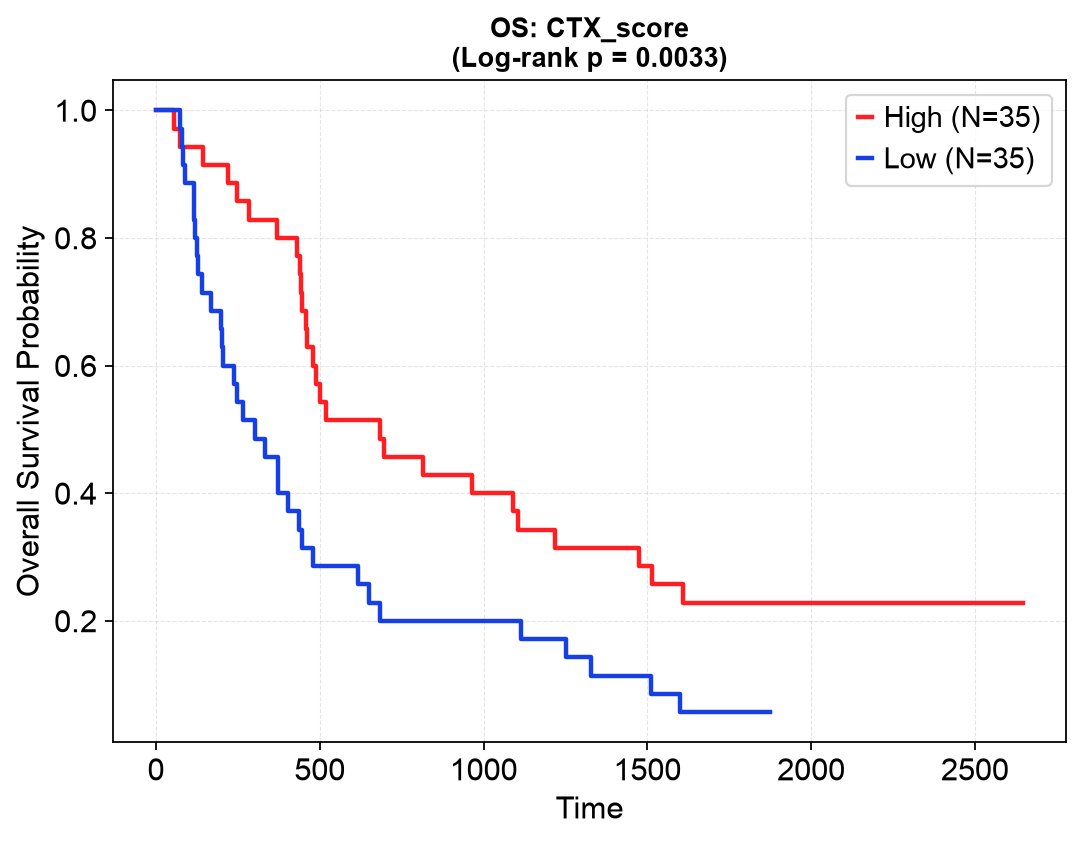

In [16]:
PATIENT_COL = 'patient'
SCORE_COL = 'Tpctx_score'
PFS_TIME = 'PFS'
PFS_EVENT = 'PFS_censor'
OS_TIME = 'OS'
OS_EVENT = 'OS_censor'

temp = adata[adata.obs['annotation_fin2'] == 'CD8+Tpex_ctx']
obs_df = temp.obs[[PATIENT_COL, SCORE_COL, PFS_TIME, PFS_EVENT, OS_TIME, OS_EVENT]].copy()

for col in [SCORE_COL, PFS_TIME, PFS_EVENT, OS_TIME, OS_EVENT]:
    obs_df[col] = pd.to_numeric(obs_df[col], errors='coerce')

pfs_cell = obs_df.dropna(subset=[SCORE_COL, PFS_TIME, PFS_EVENT])
df_pfs = pfs_cell.groupby(PATIENT_COL).agg({
    SCORE_COL: 'mean',
    PFS_TIME: 'first',
    PFS_EVENT: 'first'
}).reset_index()

pfs_median = df_pfs[SCORE_COL].median()
df_pfs['group'] = (df_pfs[SCORE_COL] >= pfs_median).astype(int)

os_cell = obs_df.dropna(subset=[SCORE_COL, OS_TIME, OS_EVENT])
df_os = os_cell.groupby(PATIENT_COL).agg({
    SCORE_COL: 'mean',
    OS_TIME: 'first',
    OS_EVENT: 'first'
}).reset_index()

# Stratify OS by median score
os_median = df_os[SCORE_COL].median()
df_os['group'] = (df_os[SCORE_COL] >= os_median).astype(int)

# 4. Plot Kaplan-Meier Curves
fig, ax = plt.subplots(1, 1, figsize=(7, 5.5))
kmf = KaplanMeierFitter()

high_os = df_os[df_os['group'] == 1]
low_os = df_os[df_os['group'] == 0]

kmf.fit(high_os[OS_TIME], event_observed=high_os[OS_EVENT], label=f'High (N={len(high_os)})')
kmf.plot_survival_function(ax=ax, color='#FF1F22', ci_show=False, linewidth=2.0)

kmf.fit(low_os[OS_TIME], event_observed=low_os[OS_EVENT], label=f'Low (N={len(low_os)})')
kmf.plot_survival_function(ax=ax, color='#173FE6', ci_show=False, linewidth=2.0)

lr_os = logrank_test(high_os[OS_TIME], low_os[OS_TIME], high_os[OS_EVENT], low_os[OS_EVENT])
p_val_os_str = f"{lr_os.p_value:.2e}" if lr_os.p_value < 0.001 else f"{lr_os.p_value:.4f}"
ax.set_title(f'OS: CTX_score\n(Log-rank p = {p_val_os_str})', fontsize=12, fontweight='bold')
ax.set_xlabel('Time')
ax.set_ylabel('Overall Survival Probability')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
# plt.savefig(f"{today}_OS_CTX_score.pdf", bbox_inches="tight", dpi=600)
plt.show()

### Kmplot

In [9]:
df=pd.read_csv('/home/leethargic/NSCLC_revision/LKC/km_PDL1_allcancer.txt', sep='\t')
df

,Sample,Expression (1=high),Expression,Time (months),Event
0,AZ1911_049TE,1,3328.333333,21.00,0
1,AZ2008_39TE,1,5988.458333,16.20,1
2,IMVigor_SAM00b9e5c52da9,0,554.395833,1.91,1
3,IMVigor_SAM0257bbbbd388,0,456.062500,15.64,1
4,IMVigor_SAM025b45c27e05,0,873.104167,8.77,1
...,...,...,...,...,...
409,TE2004_71_atr,1,8396.187500,3.63,1
410,TE2004_72_atr,1,3026.708333,14.73,0
411,TE2004_73_atr,1,6052.812500,14.73,0
412,TE2004_74_atr,1,5070.708333,16.40,0


In [10]:
sc.set_figure_params(figsize=(7,7))

findfont: Failed to find font weight medium, now using 400.


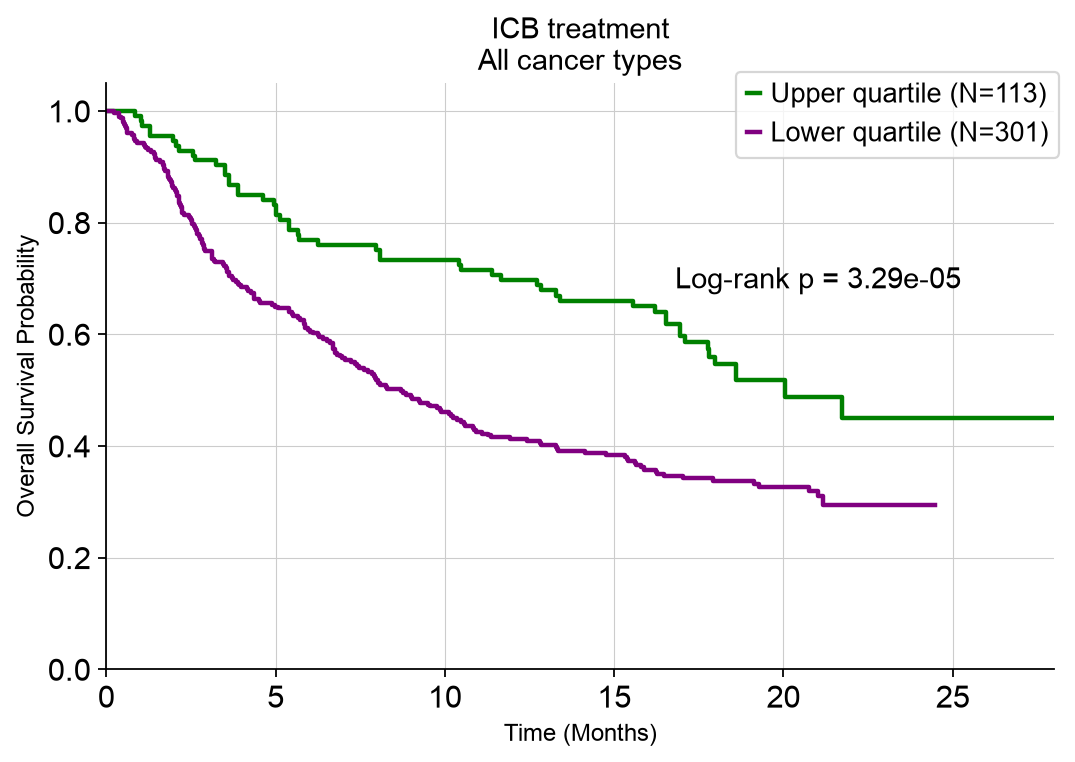

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

# 1. Clean missing values across key survival columns
df_clean = df.dropna(subset=['Time (months)', 'Event', 'Expression (1=high)']).copy()

# 2. Use KM Plotter's pre-calculated best-cutoff stratification directly
df_clean['group'] = df_clean['Expression (1=high)'].map({1: 'Upper quartile', 0: 'Lower quartile'})

group_labels = ['Upper quartile', 'Lower quartile']
colors = ['green', 'purple']

# 3. Two-sample log-rank test
high_mask = df_clean['Expression (1=high)'] == 1
low_mask = df_clean['Expression (1=high)'] == 0

lr_res = logrank_test(
    durations_A=df_clean.loc[high_mask, 'Time (months)'],
    durations_B=df_clean.loc[low_mask, 'Time (months)'],
    event_observed_A=df_clean.loc[high_mask, 'Event'],
    event_observed_B=df_clean.loc[low_mask, 'Event']
)
p_val = lr_res.p_value

# 4. Plot Kaplan-Meier curves without ticks
fig, ax = plt.subplots(figsize=(7, 5))
kmf = KaplanMeierFitter()

for g_label, col in zip(group_labels, colors):
    mask = df_clean['group'] == g_label
    n_pts = mask.sum()

    kmf.fit(
        durations=df_clean.loc[mask, 'Time (months)'],
        event_observed=df_clean.loc[mask, 'Event'],
        label=f"{g_label} (N={n_pts})"
    )
    kmf.plot_survival_function(
        ax=ax,
        ci_show=False,
        show_censors=False,
        color=col,
        lw=2.0
    )

# Formatting
ax.set_title('ICB treatment\nAll cancer types', fontsize=13)
ax.set_xlabel('Time (Months)', fontsize=11)
ax.set_ylabel('Overall Survival Probability', fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 28)

p_text = f"Log-rank p = {p_val:.2e}" if p_val < 0.001 else f"Log-rank p = {p_val:.4f}"
ax.annotate(
    p_text,
    xy=(0.6, 0.65),
    xycoords='axes fraction',
    fontsize=13,
    fontweight='medium',
    # bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="darkgray", lw=1)
)

ax.legend(frameon=True, fontsize=12, loc='lower left', bbox_to_anchor=(0.65, 0.85))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
# plt.savefig(f"{today}_KM_PDL1_OS.pdf", bbox_inches="tight", dpi=600)
plt.show()

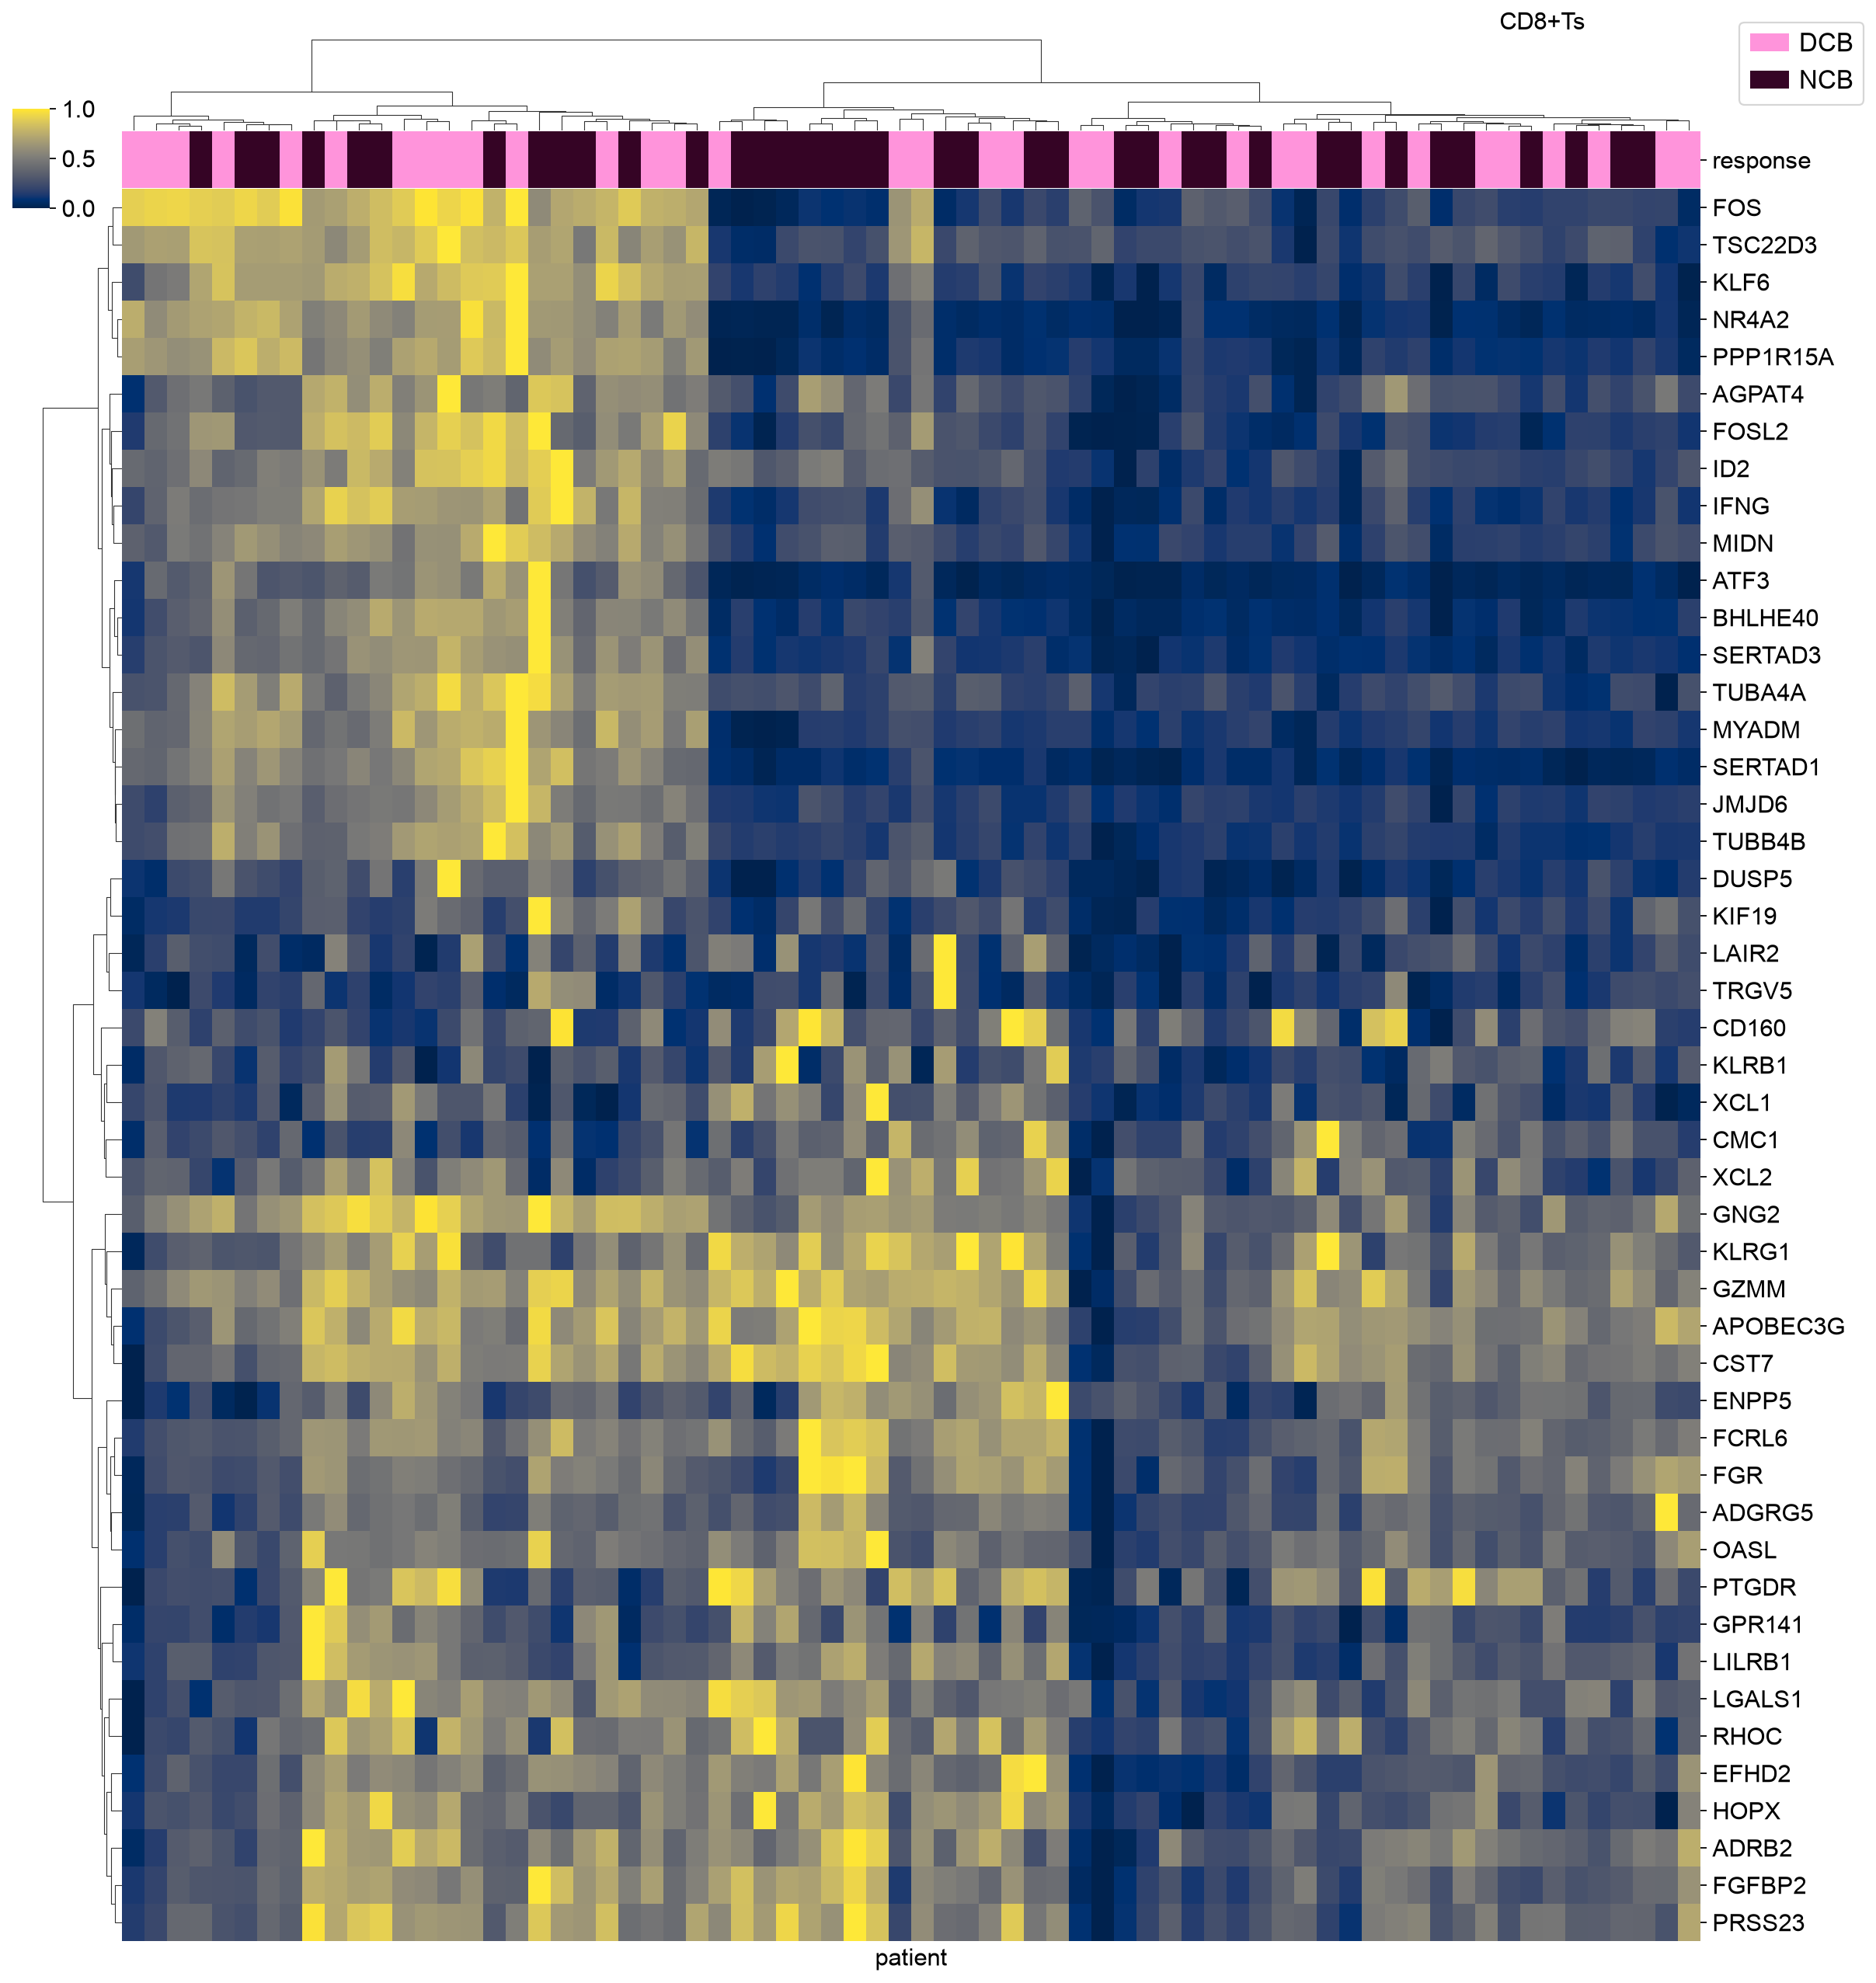

In [12]:
from matplotlib.patches import Patch
temp2 = adata[adata.obs['annotation_fin2'].isin(['CD8+Tpex','CD8+Tpex_PDCD1','CD8+Tpex_ctx','CD8+TIL','CD8+T_naive','CD8+CTL'])]
df=sc.get.obs_df(temp2, consensus_gene_list+['patient']).groupby('patient').mean()
df['response']=pd.Series(pd.Series(temp2.obs['response2'].values, index=temp2.obs['patient']).to_dict())

col2 = dict(zip(df['response'].unique(), ['#FF94DB', '#350425']))
row2 = df['response'].map(col2)

df2=df.iloc[:,:-2]
g=sns.clustermap(data=df2.T, cmap='cividis',standard_scale=0, metric='euclidean',method='ward',
                 col_colors=row2, dendrogram_ratio=(0.05,0.05), figsize=(15,16), 
                #  linewidths=0.1,linecolor='w',
                 xticklabels=False,   cbar_pos=(0, 0.9, 0.02, 0.05))

g.ax_heatmap.set_title("CD8+Ts",x=0.9, y=1.085, fontsize=14)
handles = [Patch(facecolor=col2[name]) for name in col2]
plt.legend(handles, list(col2.keys()), title=None, bbox_to_anchor=(1, 1), 
           bbox_transform=plt.gcf().transFigure, loc='upper right', handlelength=1.5, fontsize=15)
plt.savefig(f"{today}_Patient_method1_CD8_T.pdf", dpi=600, bbox_inches='tight')

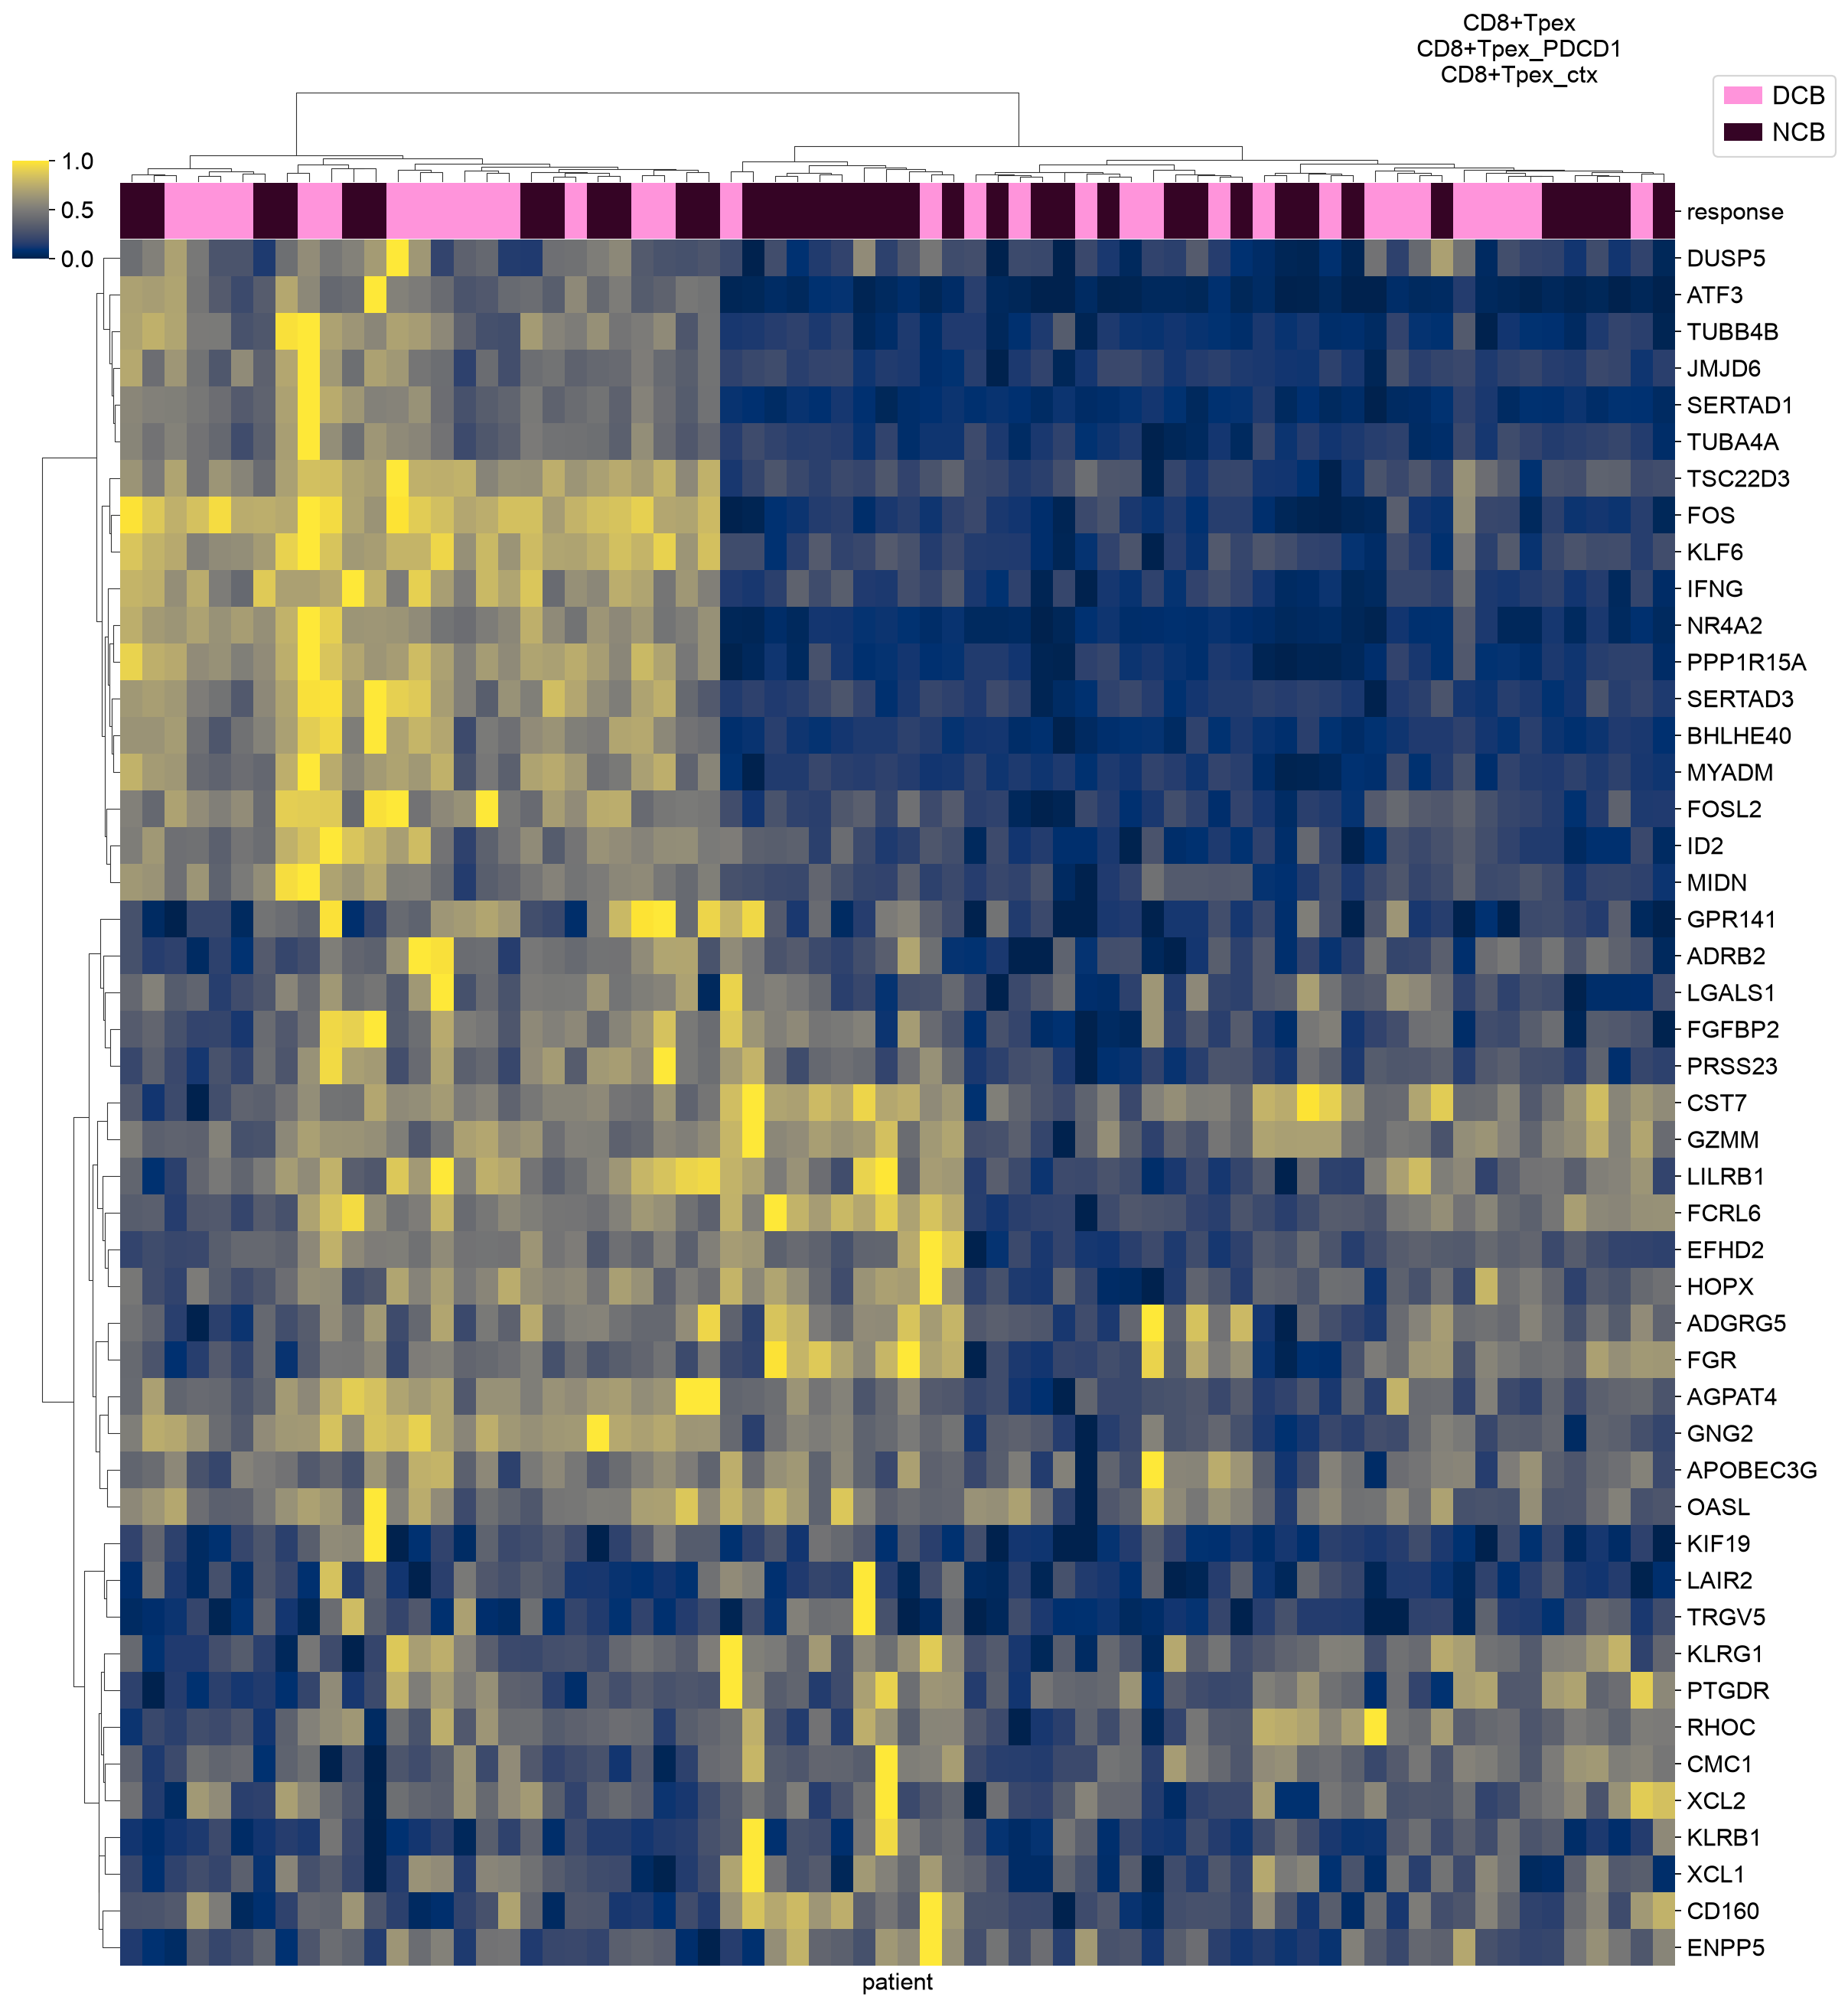

In [22]:
temp2 = adata[adata.obs['annotation_fin2'].isin(['CD8+Tpex','CD8+Tpex_PDCD1','CD8+Tpex_ctx'])]
df=sc.get.obs_df(temp2, consensus_gene_list+['patient']).groupby('patient').mean()
df['response']=pd.Series(pd.Series(temp2.obs['response2'].values, index=temp2.obs['patient']).to_dict())

col2 = dict(zip(df['response'].unique(), ['#FF94DB', '#350425']))
row2 = df['response'].map(col2)

df2=df.iloc[:,:-2]
g=sns.clustermap(data=df2.T, cmap='cividis',standard_scale=0, metric='euclidean',method='ward',
                 col_colors=row2, dendrogram_ratio=(0.05,0.05), figsize=(15,16), 
                #  linewidths=0.1,linecolor='w',
                 xticklabels=False,   cbar_pos=(0, 0.9, 0.02, 0.05))

g.ax_heatmap.set_title("CD8+Tpex\nCD8+Tpex_PDCD1\nCD8+Tpex_ctx",x=0.9, y=1.085, fontsize=14)
handles = [Patch(facecolor=col2[name]) for name in col2]
plt.legend(handles, list(col2.keys()), title=None, bbox_to_anchor=(1, 1), 
           bbox_transform=plt.gcf().transFigure, loc='upper right', handlelength=1.5, fontsize=15)

plt.savefig(f"{today}_Patient_Tpexs_Method1.pdf", dpi=600, bbox_inches='tight')

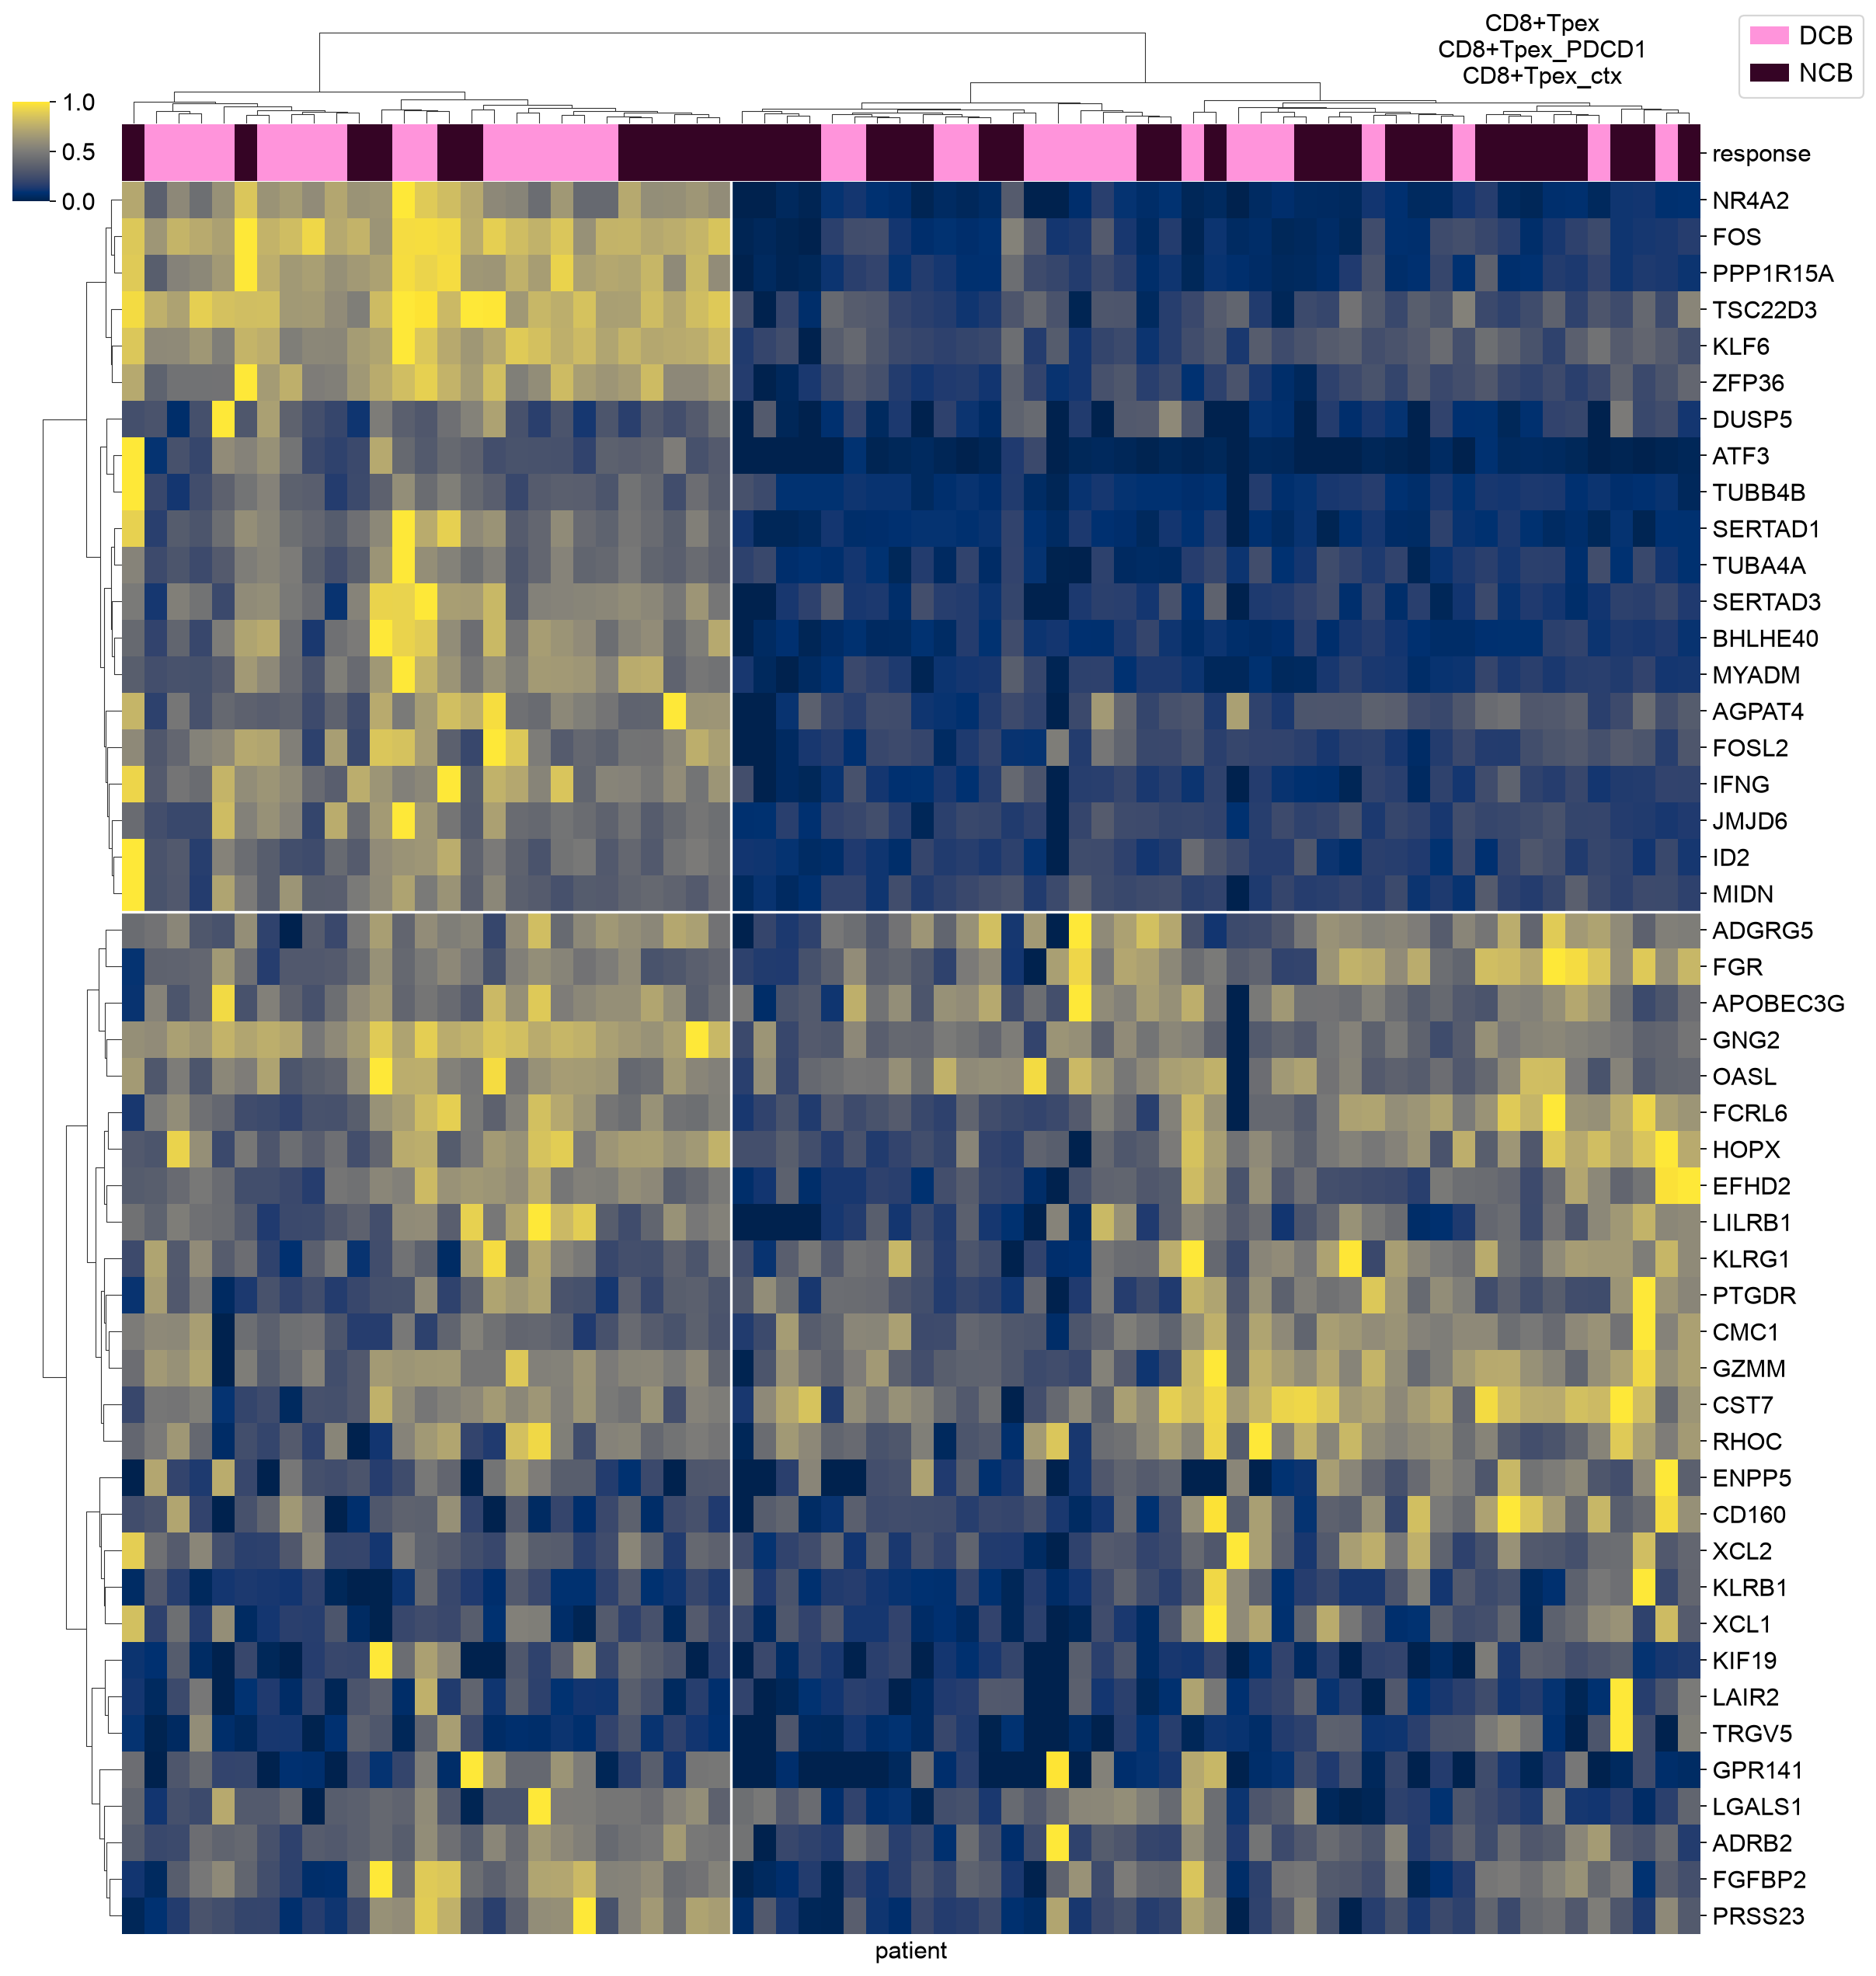

In [92]:
temp2 = adata[(adata.obs['annotation_fin2'].isin(['CD8+Tpex','CD8+Tpex_PDCD1','CD8+Tpex_ctx']))&(adata.obs['time']=='post')]
df=sc.get.obs_df(temp2, consensus_gene_list+['patient']).groupby('patient').mean()
df['response']=pd.Series(pd.Series(temp2.obs['response2'].values, index=temp2.obs['patient']).to_dict())
# df['time']=pd.Series(pd.Series(temp2.obs['time'].values, index=temp2.obs['patient']).to_dict())

col2 = dict(zip(df['response'].unique(), ['#FF94DB', '#350425']))
row2 = df['response'].map(col2)
# col3 = dict(zip(df['time'].unique(), ['#E003F6','#FFC820']))
# row3 = df['time'].map(col3)

df2=df.iloc[:,:-1]
g=sns.clustermap(data=df2.T, cmap='cividis',standard_scale=0, metric='euclidean',method='ward',
                 col_colors=row2, dendrogram_ratio=(0.05,0.05), figsize=(15,16), 
                #  linewidths=0.1,linecolor='w',
                 xticklabels=False,   cbar_pos=(0, 0.9, 0.02, 0.05))

g.ax_heatmap.axvline(x=27, color='w', linestyle='-', linewidth=1.5)
g.ax_heatmap.axhline(y=20, color='w', linestyle='-', linewidth=1.5)

g.ax_heatmap.set_title("CD8+Tpex\nCD8+Tpex_PDCD1\nCD8+Tpex_ctx",x=0.9, y=1.05, fontsize=14)
handles = [Patch(facecolor=col2[name]) for name in col2]
# handles += [Patch(facecolor=col3[name]) for name in col3]
plt.legend(handles, list(col2.keys()), title=None, bbox_to_anchor=(1, 1), 
           bbox_transform=plt.gcf().transFigure, loc='upper right', handlelength=1.5, fontsize=15)
plt.savefig(f"{today}_CD8_Tpex_Heatmap_post_only.pdf", dpi=600, bbox_inches='tight')

### PAM >> Nearest Centroid 

In [10]:
from sksurv.ensemble import (
    ComponentwiseGradientBoostingSurvivalAnalysis,
    GradientBoostingSurvivalAnalysis,
    RandomSurvivalForest
)

import seaborn as sns
from scipy.stats import zscore
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc

from sksurv.linear_model import CoxPHSurvivalAnalysis, CoxnetSurvivalAnalysis, IPCRidge
from sksurv.svm import FastSurvivalSVM
from sksurv.util import Surv

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestCentroid
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics.pairwise import rbf_kernel

try:
    from xgboost import XGBClassifier
    has_xgboost = True
except ImportError:
    has_xgboost = False


class KernelPLS:
    def __init__(self, n_components=1, gamma=None):
        self.pls = PLSRegression(n_components=n_components)
        self.gamma = gamma
        self.X_train_ = None
        
    def fit(self, X, y):
        self.X_train_ = X
        K = rbf_kernel(X, X, gamma=self.gamma)
        self.pls.fit(K, y)
        
    def predict(self, X):
        K = rbf_kernel(X, self.X_train_, gamma=self.gamma)
        return self.pls.predict(K)

class PLSR_GLM:
    def __init__(self, n_components=1):
        self.pls = PLSRegression(n_components=n_components)
        self.lr = LogisticRegression(random_state=42)
        
    def fit(self, X, y):
        self.pls.fit(X, y)
        X_pls = self.pls.transform(X)
        self.lr.fit(X_pls, y)
        
    def predict_proba(self, X):
        X_pls = self.pls.transform(X)
        return self.lr.predict_proba(X_pls)

In [ ]:
tpex_cells = adata[adata.obs['annotation_fin2'] == 'CD8+Tpex_ctx'].copy()

patient_df = tpex_cells.obs.groupby('patient').agg(
    Tpex_score=('Tpctx_score', 'mean'),
    PDL1=('PDL1', 'mean'),
    PFS=('PFS', 'first'),
    PFS_censor=('PFS_censor', 'first')
).reset_index()

patient_df = patient_df.dropna(subset=['PFS', 'PFS_censor', 'Tpex_score', 'PDL1'])
for col in ['Tpex_score', 'PDL1', 'PFS', 'PFS_censor']:
    patient_df[col] = pd.to_numeric(patient_df[col], errors='coerce')

y_binary = patient_df['PFS_censor'].values.astype(int)
y_time = patient_df['PFS'].values
y_surv = Surv.from_arrays(
    event=patient_df['PFS_censor'].astype(bool).values,
    time=y_time
)

X_raw = patient_df[['Tpex_score', 'PDL1']].values

model_configs = {
    'CoxPH (Standard)': {'type': 'survival'},
    'Coxnet (ElasticNet)': {'type': 'survival'},
    'FastSurvivalSVM (Rank)': {'type': 'survival'},
    'IPCRidge (AFT)': {'type': 'survival'},
    'Component-wise Boost': {'type': 'survival'},
    'GLMNET': {'type': 'classifier'},
    'Nearest Centroid': {'type': 'nearest_centroid'},
    'KERNEL PLS': {'type': 'kernel_pls'},
    'plsRglm': {'type': 'plsr_glm'},
}

def get_model(algo_name):
    if algo_name == 'CoxPH (Standard)':
        return CoxPHSurvivalAnalysis()
    elif algo_name == 'Coxnet (ElasticNet)':
        return CoxnetSurvivalAnalysis(l1_ratio=0.5, alpha_min_ratio=0.01)
    elif algo_name == 'FastSurvivalSVM (Rank)':
        return FastSurvivalSVM(rank_ratio=1.0, max_iter=1000, random_state=42)
    elif algo_name == 'IPCRidge (AFT)':
        return IPCRidge(alpha=1.0)
    elif algo_name == 'Component-wise Boost':
        return ComponentwiseGradientBoostingSurvivalAnalysis(n_estimators=50, learning_rate=0.05, random_state=42)
    elif algo_name == 'GLMNET':
        return LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, max_iter=5000, random_state=42)
    elif algo_name == 'Nearest Centroid':
        return NearestCentroid()
    elif algo_name == 'KERNEL PLS':
        return KernelPLS(n_components=1)
    elif algo_name == 'plsRglm':
        return PLSR_GLM(n_components=1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

feature_keys = [
    'Univariate: ctx_score',
    'Univariate: PDL1',
    'Multivariate (2 Features)',
    'z_ctx_score + z_PDL1'
]

for algo_name, config in model_configs.items():
    for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X_raw, y_binary)):
        X_train_raw, X_test_raw = X_raw[train_idx], X_raw[test_idx]
        y_surv_train = y_surv[train_idx]
        y_train_binary = y_binary[train_idx]
        y_binary_test = y_binary[test_idx]
        
        if len(np.unique(y_binary_test)) < 2:
            continue
            
        mean_tpex, std_tpex = np.mean(X_train_raw[:, 0]), np.std(X_train_raw[:, 0])
        mean_pdl1, std_pdl1 = np.mean(X_train_raw[:, 1]), np.std(X_train_raw[:, 1])
        std_tpex = std_tpex if std_tpex > 0 else 1.0
        std_pdl1 = std_pdl1 if std_pdl1 > 0 else 1.0
        
        z_tpex_train = (X_train_raw[:, 0] - mean_tpex) / std_tpex
        z_pdl1_train = (X_train_raw[:, 1] - mean_pdl1) / std_pdl1
        
        z_tpex_test = (X_test_raw[:, 0] - mean_tpex) / std_tpex
        z_pdl1_test = (X_test_raw[:, 1] - mean_pdl1) / std_pdl1
        
        condition_datasets = {
            'Univariate: ctx_score': (z_tpex_train.reshape(-1, 1), z_tpex_test.reshape(-1, 1)),
            'Univariate: PDL1': (z_pdl1_train.reshape(-1, 1), z_pdl1_test.reshape(-1, 1)),
            'Multivariate (2 Features)': (np.column_stack([z_tpex_train, z_pdl1_train]), np.column_stack([z_tpex_test, z_pdl1_test])),
            'z_ctx_score + z_PDL1': ((z_tpex_train + z_pdl1_train).reshape(-1, 1), (z_tpex_test + z_pdl1_test).reshape(-1, 1))
        }
        
        for feat_label in feature_keys:
            X_tr, X_te = condition_datasets[feat_label]
            model = get_model(algo_name)
            
            try:
                if config['type'] == 'survival':
                    model.fit(X_tr, y_surv_train)
                    # IPCRidge predicts log-survival time; invert so higher value = higher hazard/risk
                    if algo_name == 'IPCRidge (AFT)':
                        preds = -model.predict(X_te)
                    else:
                        preds = model.predict(X_te)
                elif config['type'] in ('classifier', 'plsr_glm', 'xgb'):
                    model.fit(X_tr, y_train_binary)
                    preds = model.predict_proba(X_te)[:, 1]
                elif config['type'] == 'kernel_pls':
                    model.fit(X_tr, y_train_binary)
                    preds = model.predict(X_te).ravel()
                elif config['type'] == 'nearest_centroid':
                    model.fit(X_tr, y_train_binary)
                    c0, c1 = model.centroids_[0], model.centroids_[1]
                    dist_to_0 = np.linalg.norm(X_te - c0, axis=1)
                    dist_to_1 = np.linalg.norm(X_te - c1, axis=1)
                    preds = dist_to_0 - dist_to_1
                
                # Calculate ROC-AUC against binary event status
                fpr, tpr, _ = roc_curve(y_binary_test, preds)
                score_auc = auc(fpr, tpr)
                if score_auc < 0.5:
                    fpr, tpr, _ = roc_curve(y_binary_test, -preds)
                    score_auc = auc(fpr, tpr)
            except Exception:
                continue
                
            cv_results.append({
                'Algorithm': algo_name,
                'Feature Condition': feat_label,
                'Fold': fold_idx + 1,
                'Accuracy (ROC-AUC)': score_auc
            })

df_cv_results = pd.DataFrame(cv_results)
summary_stats = df_cv_results.groupby(['Algorithm', 'Feature Condition'])['Accuracy (ROC-AUC)'].agg(['mean', 'std']).reset_index()
summary_stats['mean'] = summary_stats['mean'].round(4)
summary_stats['std'] = summary_stats['std'].round(4)
pivot_summary = summary_stats.pivot(index='Algorithm', columns='Feature Condition', values=['mean', 'std'])
pivot_summary

mean                   \
Feature Condition      Multivariate (2 Features) Univariate: PDL1   
Algorithm                                                           
Component-wise Boost                      0.7667           0.7125   
CoxPH (Standard)                          0.7833           0.7125   
Coxnet (ElasticNet)                       0.7833           0.7125   
FastSurvivalSVM (Rank)                    0.8083           0.7125   
GLMNET                                    0.7583           0.7125   
IPCRidge (AFT)                            0.7917           0.7125   
KERNEL PLS                                0.7833           0.6958   
Nearest Centroid                          0.8500           0.8167   
plsRglm                                   0.7583           0.7125   

                                                                   \
Feature Condition      Univariate: ctx_score z_ctx_score + z_PDL1   
Algorithm                                                           
Component-wise Boost                  0.7167               0.8000   
CoxPH (Standard)                      0.7167               0.8000   
Coxnet (ElasticNet)                   0.7167               0.8000   
FastSurvivalSVM (Rank)                0.7167               0.8000   
GLMNET                                0.7167               0.8000   
IPCRidge (AFT)                        0.7167               0.8000   
KERNEL PLS                            0.7000               0.7917   
Nearest Centroid                      0.6583               0.8375   
plsRglm                               0.7167               0.8000   

                                             std                   \
Feature Condition      Multivariate (2 Features) Univariate: PDL1   
Algorithm                                                           
Component-wise Boost                      0.1520           0.1900   
CoxPH (Standard)                          0.1598           0.1900   
Coxnet (ElasticNet)                       0.1598           0.1900   
FastSurvivalSVM (Rank)                    0.1126           0.1900   
GLMNET                                    0.1079           0.1900   
IPCRidge (AFT)                            0.1284           0.1900   
KERNEL PLS                                0.0950           0.2071   
Nearest Centroid                          0.1087           0.1087   
plsRglm                                   0.1079           0.1900   

                                                                   
Feature Condition      Univariate: ctx_score z_ctx_score + z_PDL1  
Algorithm                                                          
Component-wise Boost                  0.0995               0.0950  
CoxPH (Standard)                      0.0995               0.0950  
Coxnet (ElasticNet)                   0.0995               0.0950  
FastSurvivalSVM (Rank)                0.0995               0.0950  
GLMNET                                0.0995               0.0950  
IPCRidge (AFT)                        0.0995               0.0950  
KERNEL PLS                            0.0543               0.0932  
Nearest Centroid                      0.1394               0.0272  
plsRglm                               0.0995               0.0950

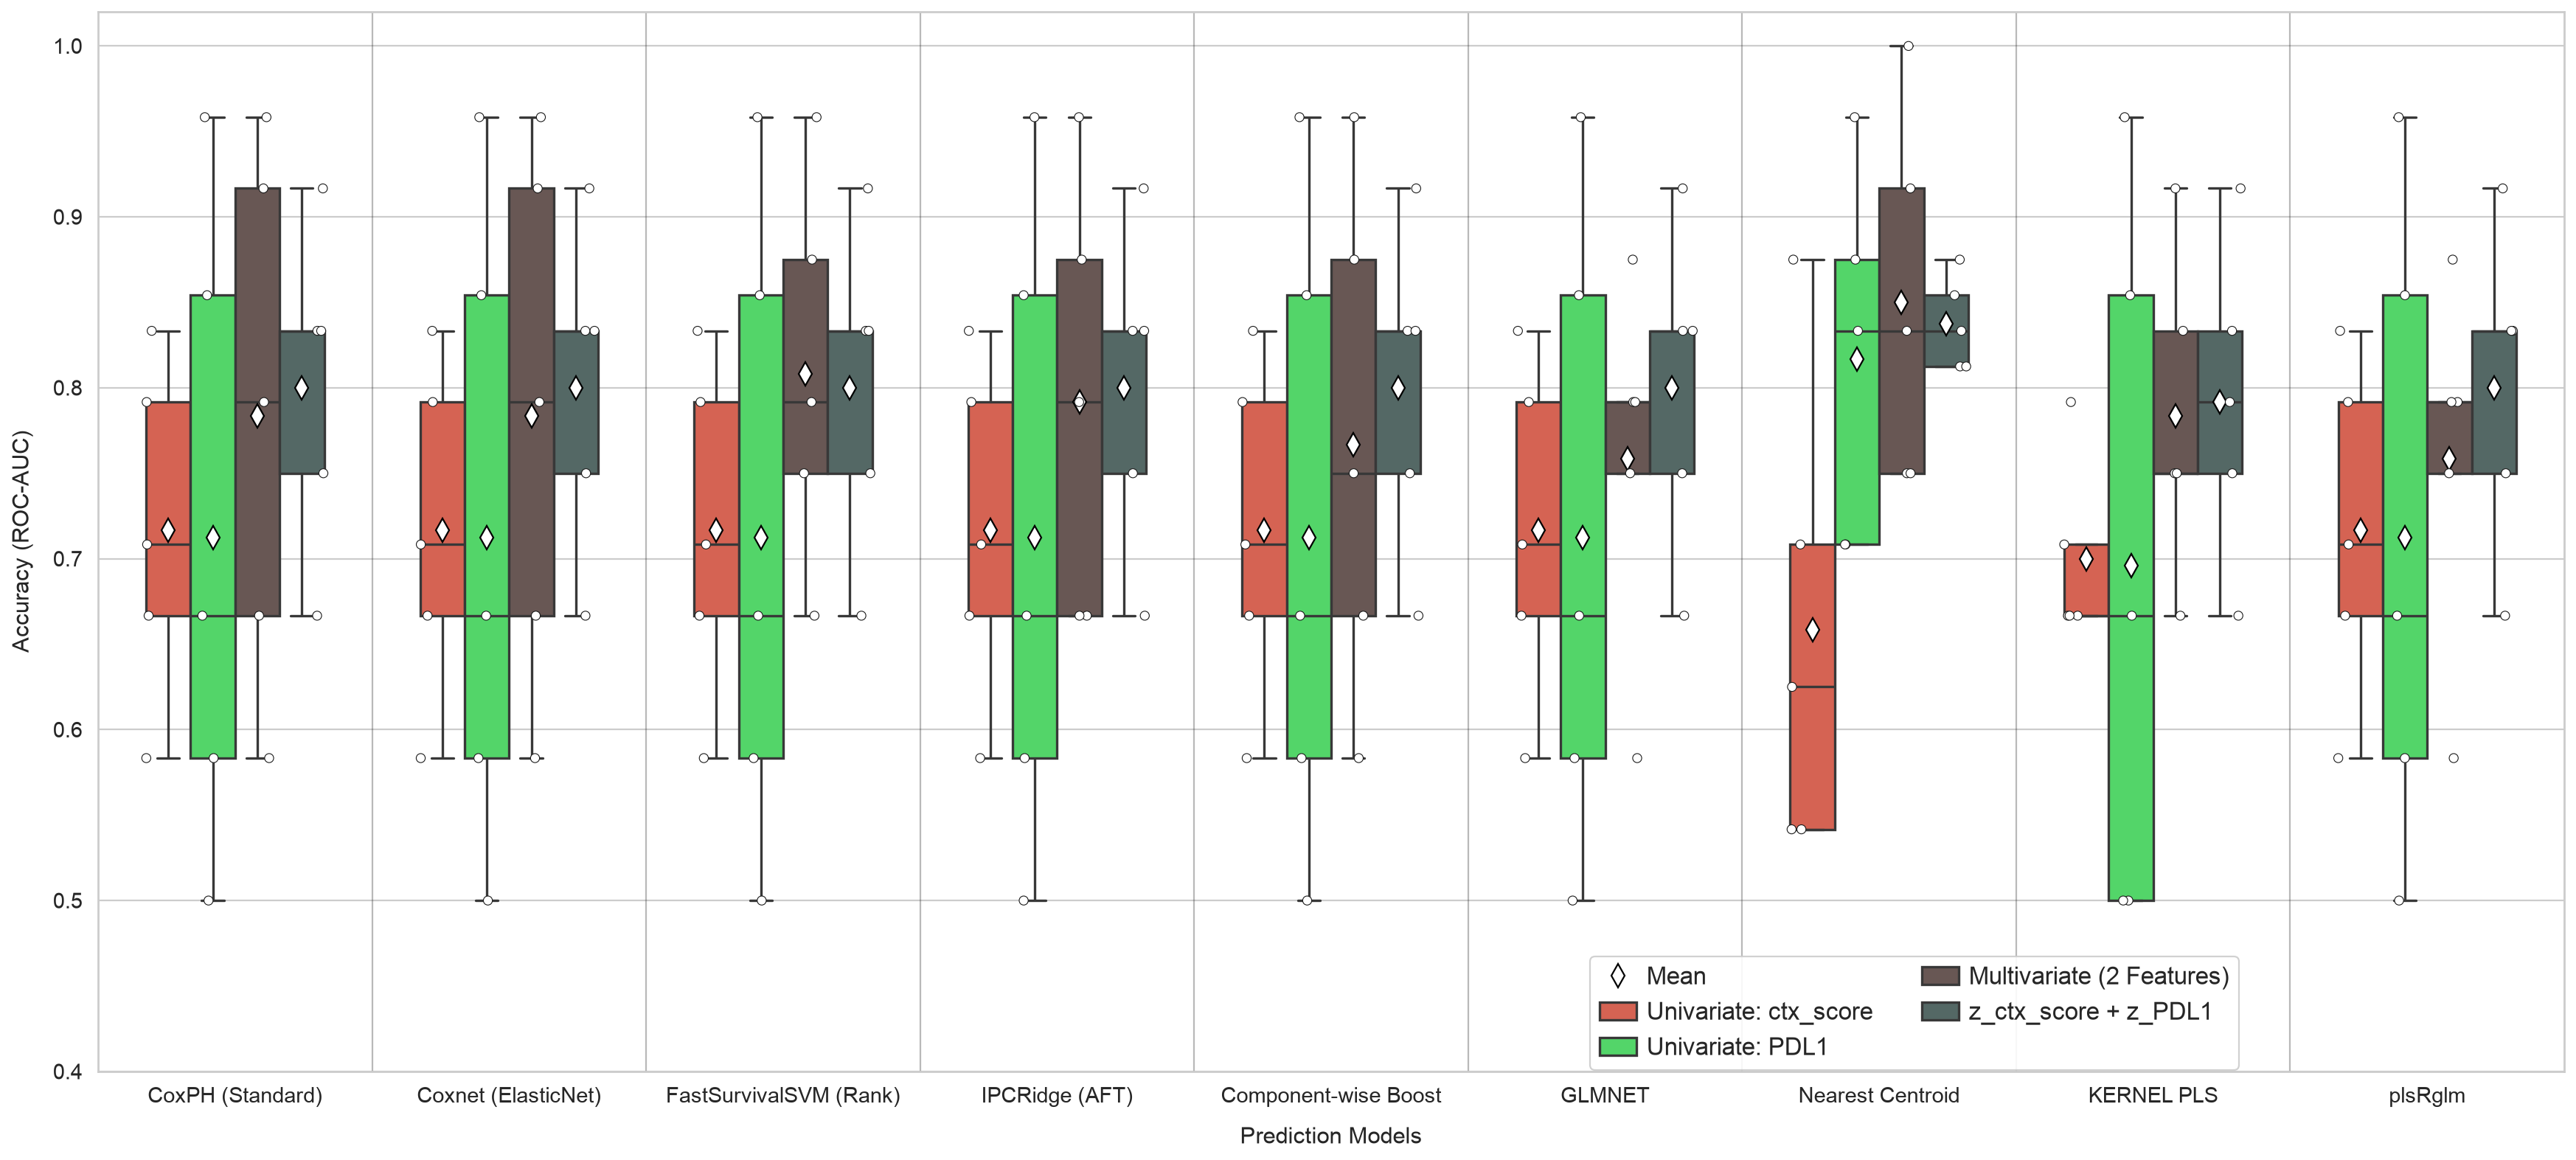

In [ ]:
plt.figure(figsize=(22, 10))
sns.set_theme(style="whitegrid")
#EB523D, #3DEB5A,#6B5451,#516B67
palette = sns.color_palette(['#EB523D', '#3DEB5A', '#6B5451', '#516B67'])

ax = sns.boxplot(
    data=df_cv_results,
    x='Algorithm',
    y='Accuracy (ROC-AUC)',
    hue='Feature Condition',
    palette=palette, width=0.65,
    linewidth=1.5,
    showmeans=True,
    meanprops={
        "marker": "d",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 10,
        "label": "Mean"
    },
    fliersize=0
)

sns.stripplot(
    data=df_cv_results,
    x='Algorithm', y='Accuracy (ROC-AUC)', hue='Feature Condition',
    palette=['w','w','w','w'],
    dodge=True, jitter=True, size=5.5,
    linewidth=0.5, edgecolor='k',  legend=False
)

for i in range(0, len(df_cv_results['Algorithm'].unique()) - 1):
    ax.axvline(x=i + 0.5, color='k', linestyle='-', alpha=0.3, lw=1.0)

plt.xlabel('Prediction Models', fontsize=14, labelpad=12)
plt.ylabel('Accuracy (ROC-AUC)', fontsize=14, labelpad=12)
plt.ylim(0.4, 1.02)
plt.xticks(ha='center', fontsize=13)
plt.yticks(fontsize=13)

handles, labels = ax.get_legend_handles_labels()
unique_legend = {}
for h, l in zip(handles, labels):
    if l not in unique_legend:
        unique_legend[l] = h

plt.legend(
    unique_legend.values(),
    unique_legend.keys(),
    bbox_to_anchor=(0.60, 0.12),
    loc='upper left',
    fontsize=15,ncols=2, handlelength=1.5,
    frameon=True, facecolor='white', framealpha=0.9
)

plt.tight_layout()
plt.savefig(f"{today}_5F-CV_ROC-AUC_comparison_plot.pdf", dpi=600, bbox_inches='tight')
plt.show()

In [23]:
df_cv_results.to_csv(f"{today}_Fold_Accuracy_results.csv", index=False)